# Notebook de visualizaciones: sesiones de compra en línea

Este notebook reúne gráficos y explicaciones para presentar los principales hallazgos del proyecto. Sus celdas muestran cómo se distribuyen las compras y cómo se desempeñó el clasificador.

## Antes de empezar

El archivo puede abrirse en Cursor, VS Code con soporte para notebooks, JupyterLab u otra aplicación compatible con `.ipynb`; no depende de Cursor.

El archivo `.gitignore` deja fuera la carpeta `.venv/` porque contiene una instalación local de Python que no se comparte con el proyecto. En una computadora nueva, se crea un entorno local y se instalan sus bibliotecas desde la carpeta principal:

**Windows (PowerShell):**

```powershell
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

**macOS o Linux:**

```bash
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
```

Luego, en el editor, se selecciona ese entorno como **intérprete** o **kernel**. Esto indica qué instalación de Python debe ejecutar las celdas; se elige la carpeta `.venv` creada en el paso anterior.

El notebook necesita que estén disponibles `datos/preparados/entrenamiento.csv` e `informes/evaluacion_final.json`. Al ejecutarse en Colab u otro servicio remoto, esos archivos también deben cargarse respetando las carpetas del proyecto.

Las gráficas descriptivas usan únicamente el archivo de entrenamiento. Para mostrar el resultado del modelo, el notebook lee el informe final ya guardado; no vuelve a abrir `prueba.csv` ni calcula otra evaluación.


## 1. Preparar el espacio de trabajo

Importamos las herramientas que necesitamos:

- **pandas** permite leer y resumir las tablas.
- **matplotlib** dibuja los gráficos.
- **json** permite leer el informe final ya guardado.

El código busca la carpeta del proyecto empezando desde la carpeta actual y subiendo por sus carpetas superiores. Así no hace falta escribir una ruta personal de Windows.


In [7]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


def buscar_carpeta_proyecto():
    """Encuentra la carpeta que contiene los datos preparados del proyecto."""
    for carpeta in (Path.cwd(), *Path.cwd().parents):
        ruta_entrenamiento = carpeta / "datos" / "preparados" / "entrenamiento.csv"
        if ruta_entrenamiento.exists():
            return carpeta
    raise FileNotFoundError(
        "No encontré datos/preparados/entrenamiento.csv. Abre el notebook desde la carpeta del proyecto."
    )


CARPETA_PROYECTO = buscar_carpeta_proyecto()
RUTA_ENTRENAMIENTO = CARPETA_PROYECTO / "datos" / "preparados" / "entrenamiento.csv"
RUTA_INFORME_FINAL = CARPETA_PROYECTO / "informes" / "evaluacion_final.json"

# Se cargan solamente las filas de entrenamiento para los gráficos descriptivos.
datos = pd.read_csv(RUTA_ENTRENAMIENTO)

# Revenue se convierte a verdadero/falso aunque el lector lo haya interpretado como texto.
if not pd.api.types.is_bool_dtype(datos["Revenue"]):
    datos["Revenue"] = (
        datos["Revenue"].astype(str).str.strip().str.lower().map(
            {"true": True, "false": False}
        )
    )

if datos["Revenue"].isna().any():
    raise ValueError("La columna Revenue contiene etiquetas que no se pudieron interpretar.")

plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

print(f"Carpeta del proyecto: {CARPETA_PROYECTO}")
print(f"Sesiones usadas para los gráficos: {len(datos):,}")
print("El conjunto de prueba no se ha cargado.")


Carpeta del proyecto: c:\Users\noomdalv\Documents\Codex\2026-10-09\referenced-chatgpt-conversation-this-is-an-2\online_shoppers_project
Sesiones usadas para los gráficos: 9,864
El conjunto de prueba no se ha cargado.


## 2. ¿Cuántas sesiones terminaron en compra?

Una **sesión** es una visita de navegación registrada en el conjunto de datos. La barra muestra cuántas sesiones terminaron en compra y cuántas no. También anotamos el porcentaje para que sea fácil comparar grupos de distinto tamaño.

Si la mayoría de las sesiones no termina en compra, la exactitud por sí sola puede dar una impresión demasiado optimista: un modelo podría acertar muchas veces prediciendo siempre “sin compra” y aun así no detectar ninguna compra.


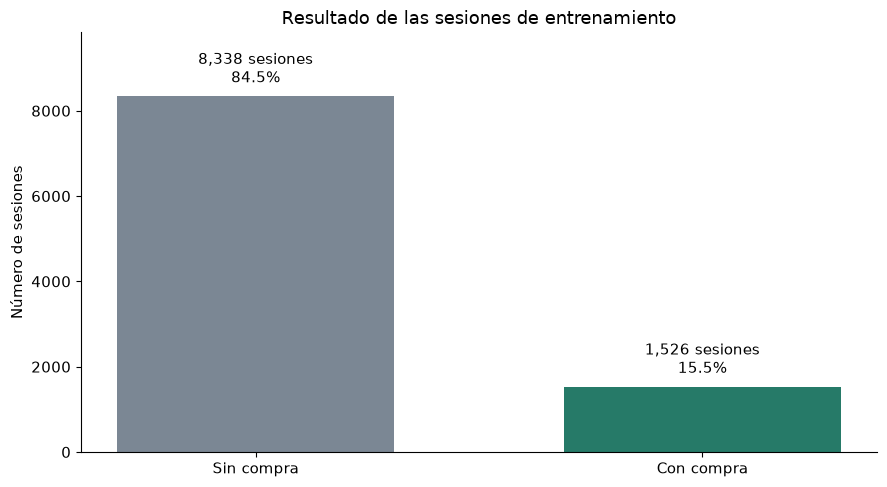

In [8]:
conteos_compra = datos["Revenue"].value_counts().reindex([False, True], fill_value=0)

figura, eje = plt.subplots()
barras = eje.bar(
    ["Sin compra", "Con compra"],
    conteos_compra.values,
    color=["#7b8794", "#267a68"],
    width=0.62,
)
eje.set_title("Resultado de las sesiones de entrenamiento")
eje.set_ylabel("Número de sesiones")
eje.set_ylim(0, conteos_compra.max() * 1.18)
eje.spines[["top", "right"]].set_visible(False)

for barra, cantidad in zip(barras, conteos_compra.values):
    porcentaje = cantidad / len(datos) * 100
    eje.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + conteos_compra.max() * 0.025,
        f"{cantidad:,} sesiones\n{porcentaje:.1f}%",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()


**Cómo leerlo:** la barra más alta representa el resultado más frecuente. El porcentaje de compras del entrenamiento puede servir como referencia para entender el desbalance de clases, pero no mide por sí solo la calidad del clasificador.


## 3. ¿Cambia la tasa de compra según el mes?

La **tasa de compra** es el número de sesiones con compra dividido por todas las sesiones de ese grupo. La etiqueta de cada barra también muestra el número de sesiones (`n`): es útil porque una tasa calculada con pocos casos puede variar mucho.

Los meses aparecen en orden de calendario. Las categorías de mes se mantienen como etiquetas, no como números.


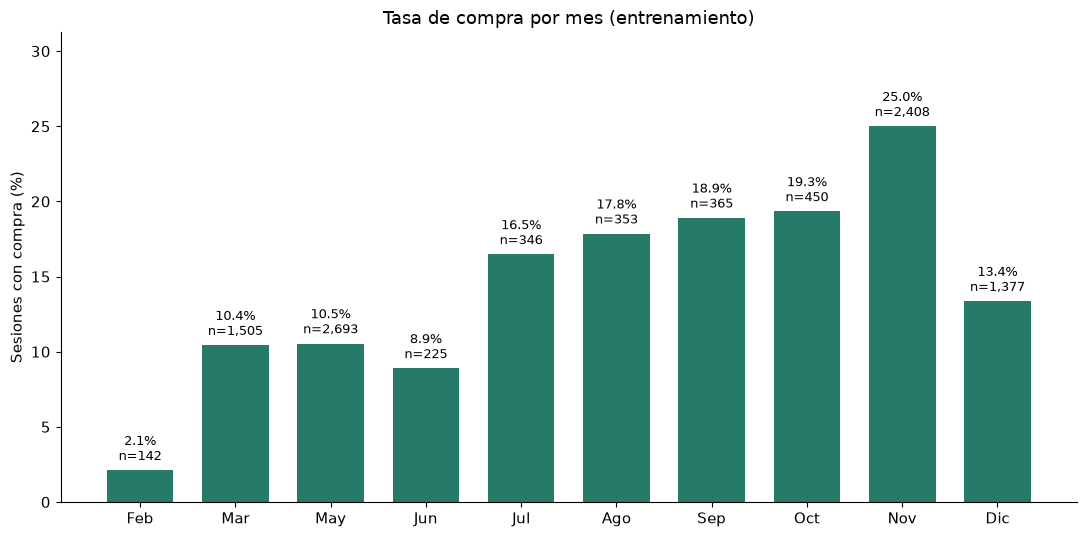

In [9]:
orden_meses = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
nombres_meses = {
    "Jan": "Ene", "Feb": "Feb", "Mar": "Mar", "Apr": "Abr",
    "May": "May", "June": "Jun", "Jul": "Jul", "Aug": "Ago",
    "Sep": "Sep", "Oct": "Oct", "Nov": "Nov", "Dec": "Dic",
}

resumen_meses = (
    datos.groupby("Month", as_index=False)
    .agg(sesiones=("Revenue", "size"), compras=("Revenue", "sum"))
)
resumen_meses["tasa_compra"] = resumen_meses["compras"] / resumen_meses["sesiones"]
resumen_meses["orden"] = resumen_meses["Month"].map(
    {mes: indice for indice, mes in enumerate(orden_meses)}
)
resumen_meses = resumen_meses.sort_values("orden")

figura, eje = plt.subplots(figsize=(11, 5.5))
marcas = range(len(resumen_meses))
barras = eje.bar(
    marcas,
    resumen_meses["tasa_compra"] * 100,
    color="#267a68",
    width=0.7,
)
eje.set_xticks(marcas, [nombres_meses.get(mes, mes) for mes in resumen_meses["Month"]])
eje.set_title("Tasa de compra por mes (entrenamiento)")
eje.set_ylabel("Sesiones con compra (%)")
eje.set_ylim(0, (resumen_meses["tasa_compra"].max() * 100) * 1.25)
eje.spines[["top", "right"]].set_visible(False)

for barra, fila in zip(barras, resumen_meses.itertuples()):
    eje.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.4,
        f"{fila.tasa_compra:.1%}\nn={fila.sesiones:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()


**Interpretación:** cada barra compara la proporción de sesiones con compra en un mes. Las diferencias describen lo observado en este conjunto de datos; no demuestran que el mes cause una compra. La temporada y la cantidad de sesiones registradas también pueden influir en la comparación.


## 4. Tasa de compra por tipo de visitante

`VisitorType` distingue visitantes nuevos, recurrentes y otros. Aquí traducimos las etiquetas solo para el gráfico; los datos originales permanecen intactos. Además de la tasa, mostramos el tamaño del grupo.


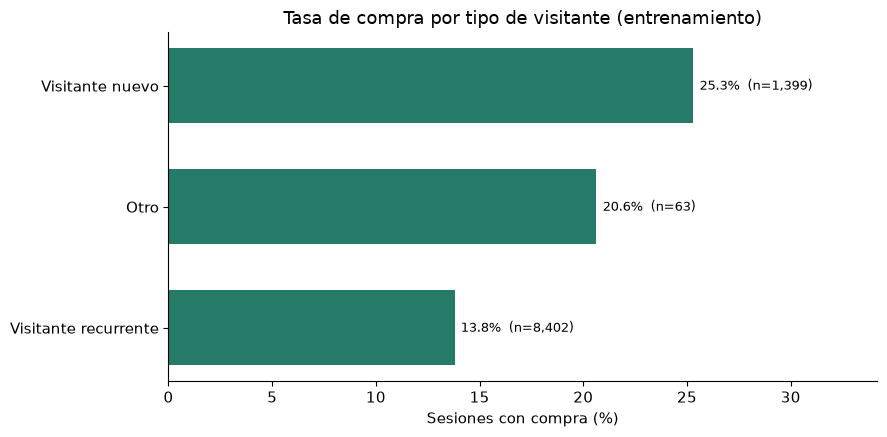

In [10]:
resumen_visitantes = (
    datos.groupby("VisitorType", as_index=False)
    .agg(sesiones=("Revenue", "size"), compras=("Revenue", "sum"))
)
resumen_visitantes["tasa_compra"] = (
    resumen_visitantes["compras"] / resumen_visitantes["sesiones"]
)
nombres_visitantes = {
    "Returning_Visitor": "Visitante recurrente",
    "New_Visitor": "Visitante nuevo",
    "Other": "Otro",
}
resumen_visitantes["nombre"] = resumen_visitantes["VisitorType"].map(nombres_visitantes)
resumen_visitantes = resumen_visitantes.sort_values("tasa_compra")

figura, eje = plt.subplots(figsize=(9, 4.5))
marcas = range(len(resumen_visitantes))
barras = eje.barh(
    marcas,
    resumen_visitantes["tasa_compra"] * 100,
    color="#267a68",
    height=0.62,
)
eje.set_yticks(marcas, resumen_visitantes["nombre"])
eje.set_title("Tasa de compra por tipo de visitante (entrenamiento)")
eje.set_xlabel("Sesiones con compra (%)")
eje.set_xlim(0, resumen_visitantes["tasa_compra"].max() * 100 * 1.35)
eje.spines[["top", "right"]].set_visible(False)

for barra, fila in zip(barras, resumen_visitantes.itertuples()):
    eje.text(
        barra.get_width() + 0.3,
        barra.get_y() + barra.get_height() / 2,
        f"{fila.tasa_compra:.1%}  (n={fila.sesiones:,})",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()


**Interpretación:** la tasa y el tamaño `n` de cada grupo se consideran en conjunto. En grupos pequeños, la tasa es menos estable. La comparación es descriptiva: el tipo de visitante no necesariamente explica por sí solo la decisión de compra.


## 5. Errores del modelo en la evaluación final

La **matriz de confusión** cruza lo que ocurrió realmente con lo que predijo el modelo:

- **Compra detectada:** hubo compra y el modelo la identificó.
- **Compra omitida:** hubo compra, pero el modelo dijo “sin compra”.
- **Falsa alarma:** no hubo compra, pero el modelo predijo que sí.
- **Sin compra detectada:** no hubo compra y el modelo acertó.

Para no volver a usar el conjunto reservado, esta celda lee los conteos del informe final ya guardado. No carga `prueba.csv` y no vuelve a calcular las métricas.


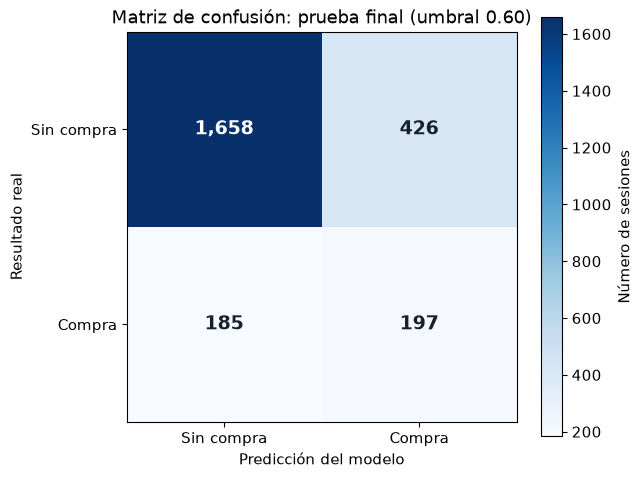

,Métrica,Resultado
0,Exactitud,0.7522
1,Precisión,0.3162
2,Recall de compra,0.5157
3,F1,0.3920
4,ROC-AUC,0.7631


In [11]:
if not RUTA_INFORME_FINAL.exists():
    raise FileNotFoundError(
        "No encontré informes/evaluacion_final.json. Primero debe existir el informe de evaluación final del proyecto."
    )

with RUTA_INFORME_FINAL.open(encoding="utf-8") as archivo:
    informe_final = json.load(archivo)

matriz = informe_final["selected_model"]["confusion_matrix"]
valores_matriz = [
    [matriz["true_negative"], matriz["false_positive"]],
    [matriz["false_negative"], matriz["true_positive"]],
]

figura, eje = plt.subplots(figsize=(6.5, 5.2))
imagen = eje.imshow(valores_matriz, cmap="Blues")
eje.set_xticks([0, 1], ["Sin compra", "Compra"])
eje.set_yticks([0, 1], ["Sin compra", "Compra"])
eje.set_xlabel("Predicción del modelo")
eje.set_ylabel("Resultado real")
eje.set_title(
    f"Matriz de confusión: prueba final (umbral {informe_final['threshold_selected_before_test']:.2f})"
)

for fila in range(2):
    for columna in range(2):
        eje.text(
            columna,
            fila,
            f"{valores_matriz[fila][columna]:,}",
            ha="center",
            va="center",
            color="white" if valores_matriz[fila][columna] > max(map(max, valores_matriz)) * 0.55 else "#17212b",
            fontsize=14,
            fontweight="bold",
        )

figura.colorbar(imagen, ax=eje, label="Número de sesiones")
plt.tight_layout()
plt.show()

metricas = informe_final["selected_model"]
tabla_metricas = pd.DataFrame(
    {
        "Métrica": ["Exactitud", "Precisión", "Recall de compra", "F1", "ROC-AUC"],
        "Resultado": [
            metricas["accuracy"], metricas["precision"], metricas["recall"],
            metricas["f1"], metricas["roc_auc"],
        ],
    }
)
display(tabla_metricas)


**Interpretación:** los aciertos aparecen en la diagonal de la matriz. “Compra omitida” representa una compra que el modelo no detectó; “Falsa alarma”, una sesión marcada como compra que no terminó en una. La importancia de cada error depende del costo asociado en el negocio.

El modelo alcanzó un recall de compra cercano al 51,6 %: identificó parte de las compras, pero dejó pasar otras. La exactitud fue aproximadamente 75,2 %. En este problema, la exactitud debe interpretarse junto con otras métricas porque la mayoría de las sesiones no termina en compra.


## 6. Conclusiones y límites

En entrenamiento, 1,526 de 9,864 sesiones terminaron en compra (15.47 %). Noviembre tuvo la tasa observada más alta (25.00 %) y febrero, la más baja (2.11 %). Estas diferencias describen el conjunto analizado; no prueban que el mes cause una compra.

Las visitas nuevas registraron una tasa de compra de 25.30 %, frente a 13.79 % en las recurrentes. El grupo `Other` alcanzó 20.63 %, pero reúne solo 63 sesiones y su tasa es menos estable. Estas asociaciones no demuestran causalidad.

En la prueba final, la regresión logística balanceada (umbral 0.60) obtuvo 75.22 % de exactitud. Detectó 197 de 382 compras, omitió 185 y generó 426 falsas alarmas. La regla que siempre predice “sin compra” alcanzó 84.51 % de exactitud, pero no detectó ninguna compra; por eso la exactitud no basta para valorar este modelo.

El modelo reconoce parte de las compras, pero aún comete numerosos errores. Es una demostración académica y no está listo para decisiones comerciales; su utilidad dependería del costo relativo de las falsas alarmas y las compras omitidas.

La evaluación se realizó una sola vez sobre sesiones reservadas y el notebook muestra el informe guardado, sin volver a evaluar `prueba.csv`. Los resultados no garantizan el mismo desempeño en otra tienda o periodo; la puntuación tampoco equivale necesariamente a una probabilidad calibrada de compra.
